In [1]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
 

In [6]:
# Load a model
model = YOLO("models/yolo26n-seg.pt")  # load a pretrained model (recommended for training)
img1 = "../images/000000017179.jpg"


In [7]:
# Inference
results = model.predict(
    source=img1,
    conf=0.25,
    device="mps",   # Mac Apple Silicon；若不支援可改成 "cpu"
    verbose=False
)

# Plot segmentation result
annotated = results[0].plot()

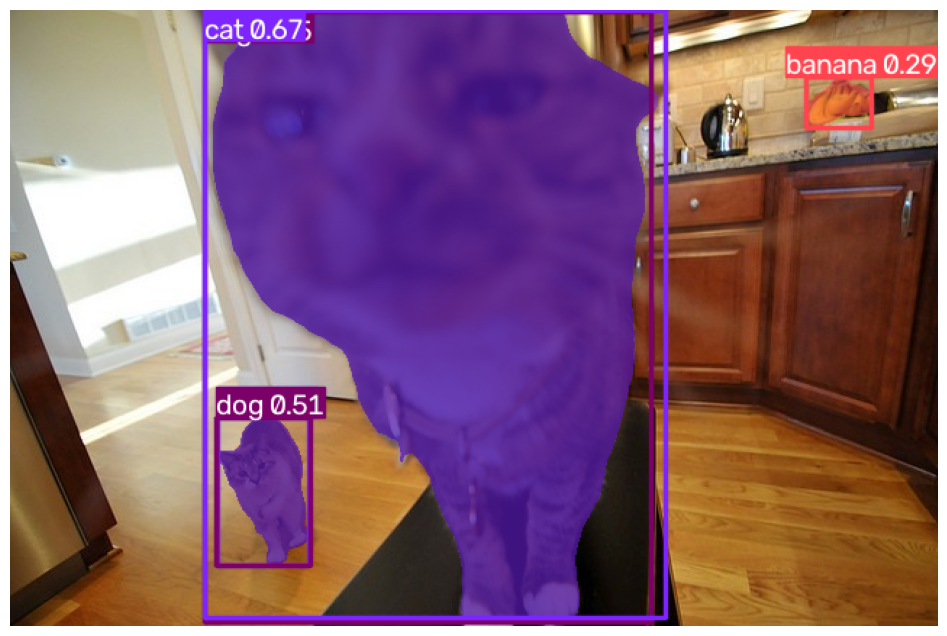

In [8]:
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

Class ID	Animal
14	bird
15	cat
16	dog
17	horse
18	sheep
19	cow
20	elephant
21	bear
22	zebra
23	giraffe

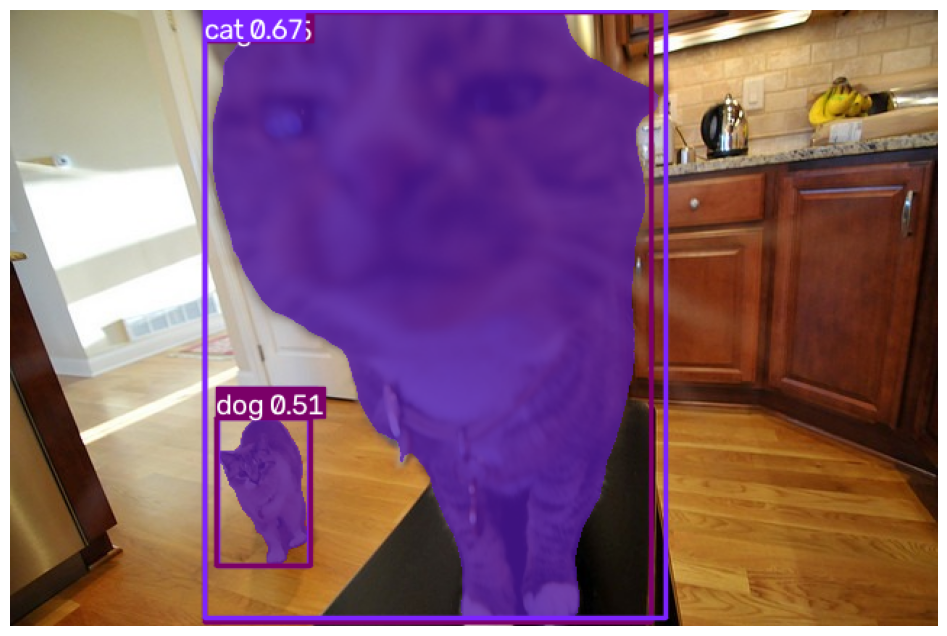

In [9]:
animal_classes = list(range(14, 24))

results = model.predict(
    source=img1,
    conf=0.25,
    classes=animal_classes,
    device="mps",
    verbose=False
)

result = results[0]

annotated = result.plot(
    boxes=True,
    masks=True,
    labels=True
)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

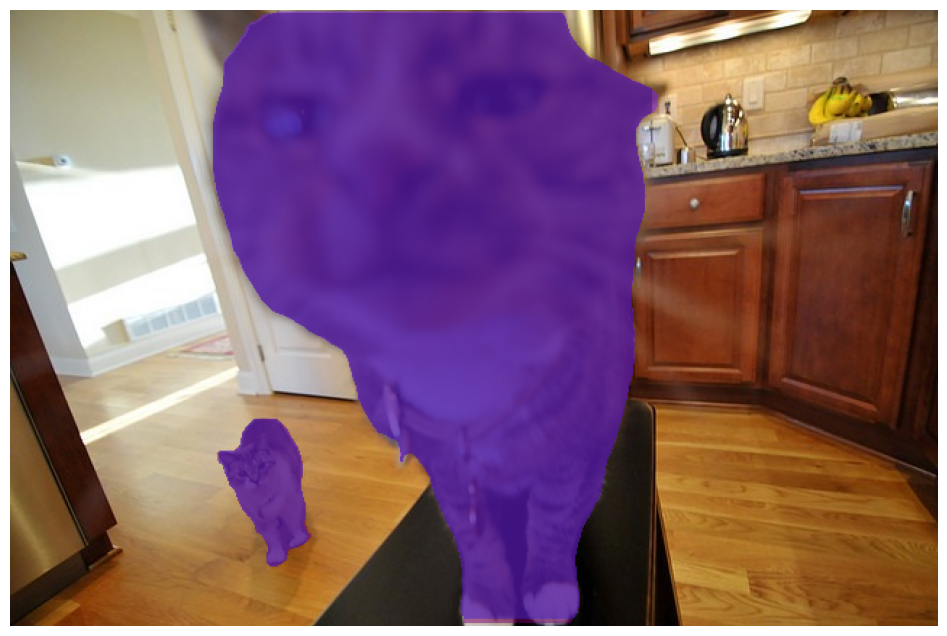

In [10]:
annotated = result.plot(
    boxes=False,
    labels=False,
    masks=True
)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

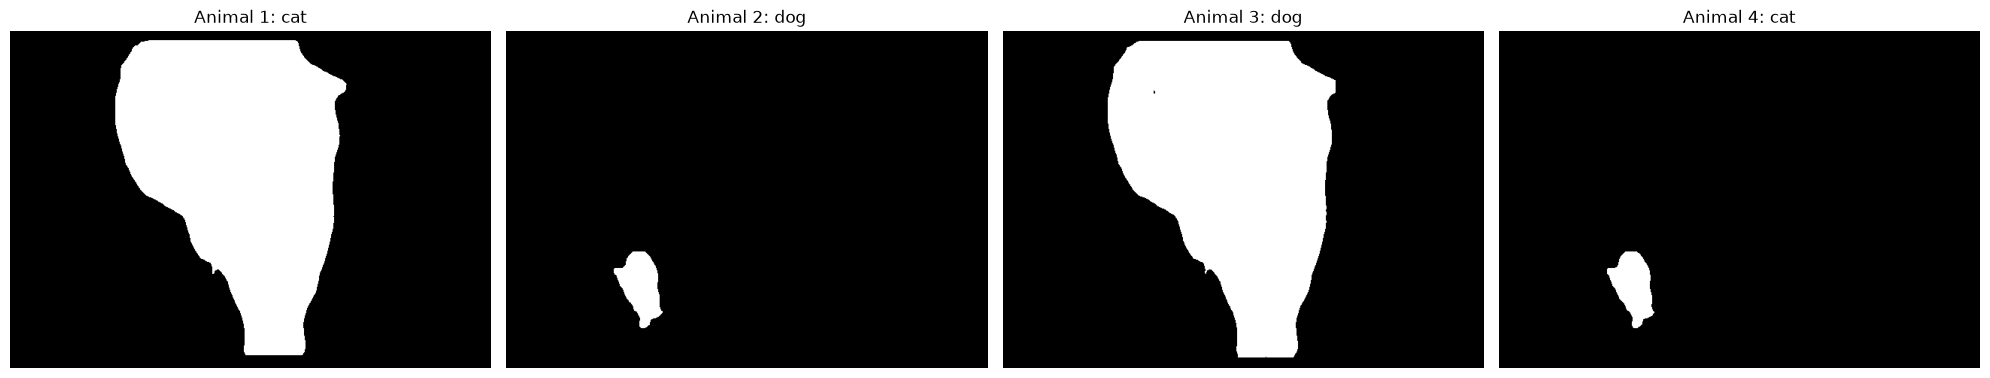

In [11]:
import numpy as np

result = results[0]

if result.masks is not None:
    masks = result.masks.data.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)

    fig, axes = plt.subplots(
        1, len(masks),
        figsize=(5 * len(masks), 5),
        squeeze=False
    )

    for i, mask in enumerate(masks):
        axes[0, i].imshow(mask, cmap="gray")
        axes[0, i].set_title(
            f"Animal {i+1}: {model.names[classes[i]]}"
        )
        axes[0, i].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No animal detected.")

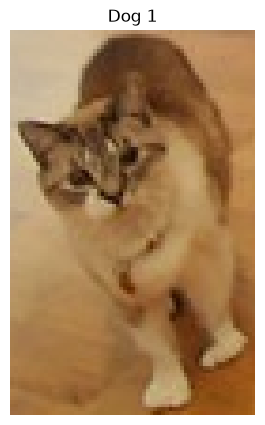

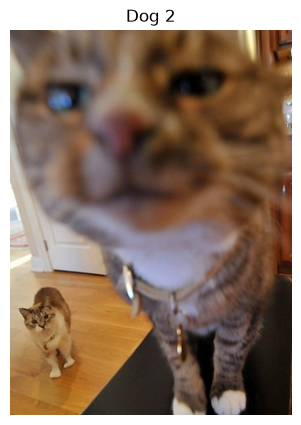

In [12]:
import cv2
import matplotlib.pyplot as plt

result = results[0]
image = cv2.imread(img1)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

dog_crops = []

for i, (box, cls) in enumerate(
    zip(result.boxes.xyxy.cpu().numpy(),
        result.boxes.cls.cpu().numpy())
):
    if model.names[int(cls)] != "dog":
        continue

    x1, y1, x2, y2 = map(int, box)

    crop = image_rgb[y1:y2, x1:x2]
    dog_crops.append({
        "image": crop,
        "offset": (x1, y1)
    })

    plt.figure(figsize=(5, 5))
    plt.imshow(crop)
    plt.title(f"Dog {len(dog_crops)}")
    plt.axis("off")
    plt.show()

In [13]:
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from PIL import Image

device = "mps" if torch.backends.mps.is_available() else "cpu"

processor = AutoProcessor.from_pretrained(
    "IDEA-Research/grounding-dino-tiny"
)

dino = AutoModelForZeroShotObjectDetection.from_pretrained(
    "IDEA-Research/grounding-dino-tiny"
).to(device)

dino.eval()

/Users/yun/anaconda3/envs/animal-metrology/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1031 17:42:30.971000 72163 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 978/978 [00:00<00:00, 6653.37it/s]


GroundingDinoForObjectDetection(
  (model): GroundingDinoModel(
    (backbone): GroundingDinoConvModel(
      (conv_encoder): GroundingDinoConvEncoder(
        (model): SwinBackbone(
          (swin): SwinModel(
            (embeddings): SwinEmbeddings(
              (patch_embeddings): SwinPatchEmbeddings(
                (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
              )
              (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (encoder): SwinEncoder(
              (layers): ModuleList(
                (0): SwinStage(
                  (blocks): ModuleList(
                    (0): SwinLayer(
                      (attention): SwinAttention(
                        (q_proj): Linear(in_features=96, out_features=96, bias=True)
                        (k_proj): Linear(in_features=96, out_features=96, bias=True)
                        (v_proj): Linear(

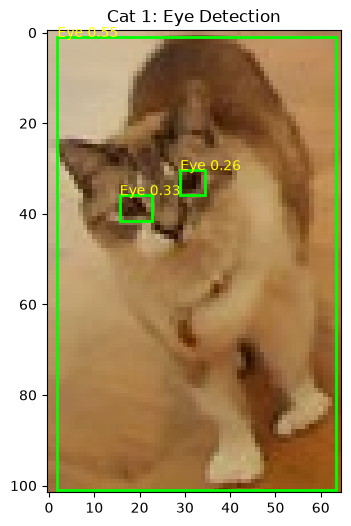

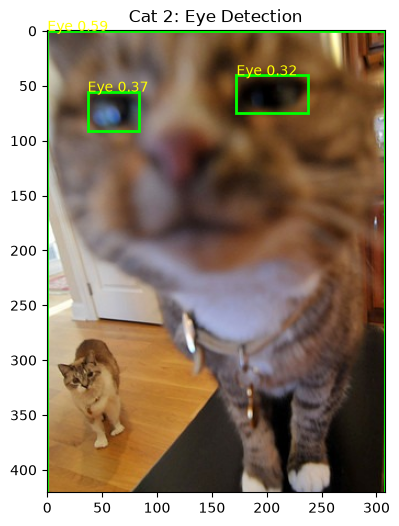

In [17]:
import matplotlib.patches as patches

for dog_idx, dog in enumerate(dog_crops):
    pil_image = Image.fromarray(dog["image"])

    inputs = processor(
        images=pil_image,
        text="Animal two eye.",
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = dino(**inputs)

    detections = processor.post_process_grounded_object_detection(
        outputs,
        inputs.input_ids,
        threshold=0.24,
        text_threshold=0.30,
        target_sizes=[pil_image.size[::-1]]
    )[0]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(pil_image)

    for box, score in zip(
        detections["boxes"],
        detections["scores"]
    ):
        x1, y1, x2, y2 = box.cpu().numpy()

        rect = patches.Rectangle(
            (x1, y1),
            x2-x1,
            y2-y1,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)

        ax.text(
            x1, y1,
            f"Eye {score:.2f}",
            color="yellow"
        )

    ax.set_title(f"Cat {dog_idx+1}: Eye Detection")
    
    ax.axis("on")
    
    plt.show()